# 07 - Generalização: gap, validação cruzada, viés e variância

- **Gap** = desempenho no treino − desempenho no teste, na métrica principal
  (F1 na classificação, RMSE na regressão). Para RMSE (erro), o sinal se inverte:
  gap **negativo** = erro maior no teste = queda fora do treino.
- **Validação cruzada K-fold (K = 5)** no treino para árvore e ensembles (média ± desvio).
- **Sistema especialista:** não há treinamento, então as regras já elaboradas são apenas
  *avaliadas* nos mesmos 5 folds (nenhum ajuste é feito).
- **Critério de diagnóstico** (explícito, para ser reproduzível):
  - *Overfitting*: gap relativo > 10% (classificação: (F1treino − F1teste)/F1teste;
    regressão: (RMSEteste − RMSEtreino)/RMSEteste).
  - *Underfitting*: não é overfitting e o desempenho no teste fica mais de 5% pior que
    o do melhor modelo (o modelo não captura padrões que outros capturam).
  - *Bem ajustado*: caso contrário.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, learning_curve

from src.config import SEED, TABLES, carregar_split, salvar_fig, salvar_tabela
from src.metrics import METRICA_PRINCIPAL, SCORING_CV, metricas_classificacao, metricas_regressao
from src.models import SistemaEspecialista, carregar_modelos

sns.set_style("whitegrid")
cv = {"classificacao": StratifiedKFold(5, shuffle=True, random_state=SEED),
      "regressao": KFold(5, shuffle=True, random_state=SEED)}
metricas = {"classificacao": pd.read_csv(TABLES / "metricas_classificacao.csv"),
            "regressao": pd.read_csv(TABLES / "metricas_regressao.csv")}

In [2]:
def validacao_cruzada(problema):
    X_train, _, y_train, _ = carregar_split(problema)
    nome_m = METRICA_PRINCIPAL[problema]
    linhas = []
    for nome, m in carregar_modelos(problema).items():
        if isinstance(m, SistemaEspecialista):
            # só avalia as regras em cada fold de validação (nada é ajustado)
            f = metricas_classificacao if problema == "classificacao" else metricas_regressao
            vals = np.array([f(y_train.iloc[va], m.predict(X_train.iloc[va]))[nome_m]
                             for _, va in cv[problema].split(X_train, y_train)])
        else:
            r = cross_validate(clone(m), X_train, y_train, cv=cv[problema],
                               scoring=SCORING_CV[problema], n_jobs=-1)
            vals = np.abs(r["test_score"])
        linhas.append({"modelo": nome, "cv_media": vals.mean(), "cv_desvio": vals.std(ddof=1),
                       **{f"fold_{i+1}": v for i, v in enumerate(vals)}})
    return pd.DataFrame(linhas)


def diagnostico(problema, cvdf):
    m = metricas[problema].pivot(index="modelo", columns="conjunto")
    nome_m = METRICA_PRINCIPAL[problema]
    tr, te = m[(nome_m, "treino")], m[(nome_m, "teste")]
    tab = pd.DataFrame({f"{nome_m}_treino": tr, f"{nome_m}_teste": te, "gap": tr - te})
    if problema == "classificacao":
        tab["gap_relativo"] = (tr - te) / te
        pior_que_melhor = te < te.max() * 0.95
        extra = {"ROC-AUC_treino": m[("ROC-AUC", "treino")], "ROC-AUC_teste": m[("ROC-AUC", "teste")]}
    else:
        tab["gap_relativo"] = (te - tr) / te
        pior_que_melhor = te > te.min() * 1.05
        extra = {"R2_treino": m[("R2", "treino")], "R2_teste": m[("R2", "teste")]}
        tab["gap_R2"] = extra["R2_treino"] - extra["R2_teste"]
    tab = tab.assign(**extra)
    tab["diagnostico"] = np.where(tab["gap_relativo"] > 0.10, "overfitting",
                                  np.where(pior_que_melhor, "underfitting", "bem ajustado"))
    tab = tab.join(cvdf.set_index("modelo")[["cv_media", "cv_desvio"]])
    return tab.loc[cvdf["modelo"]]

## 1. Classificação (métrica principal: F1)

In [3]:
cv_c = validacao_cruzada("classificacao")
salvar_tabela(cv_c, "cv_classificacao", index=False)
gen_c = diagnostico("classificacao", cv_c)
salvar_tabela(gen_c, "generalizacao_classificacao")
gen_c.round(4)

,F1_treino,F1_teste,gap,gap_relativo,ROC-AUC_treino,ROC-AUC_teste,diagnostico,cv_media,cv_desvio
modelo,,,,,,,,,
Sistema Especialista,0.7487,0.7314,0.0173,0.0237,0.9041,0.8976,underfitting,0.7488,0.0174
Árvore (sem restrição),1.0000,0.7059,0.2941,0.4167,1.0000,0.7867,overfitting,0.6986,0.0150
Árvore (ajustada),0.8242,0.7557,0.0685,0.0907,0.9653,0.8848,underfitting,0.7636,0.0231
Random Forest,0.9410,0.7926,0.1484,0.1873,0.9946,0.9394,overfitting,0.8044,0.0163
Gradient Boosting,0.9048,0.8074,0.0974,0.1207,0.9842,0.9451,overfitting,0.8191,0.0183


## 2. Regressão (métrica principal: RMSE)

In [4]:
cv_r = validacao_cruzada("regressao")
salvar_tabela(cv_r, "cv_regressao", index=False)
gen_r = diagnostico("regressao", cv_r)
salvar_tabela(gen_r, "generalizacao_regressao")
gen_r.round(4)

,RMSE_treino,RMSE_teste,gap,gap_relativo,gap_R2,R2_treino,R2_teste,diagnostico,cv_media,cv_desvio
modelo,,,,,,,,,,
Sistema Especialista,12.3313,12.5806,-0.2493,0.0198,0.0080,0.6634,0.6554,bem ajustado,12.3290,0.2638
Árvore (sem restrição),0.0000,16.7521,-16.7521,1.0000,0.6111,1.0000,0.3889,overfitting,17.1160,0.3507
Árvore (ajustada),11.8224,12.2974,-0.4751,0.0386,0.0199,0.6906,0.6707,bem ajustado,12.0849,0.2315
Random Forest,10.5062,12.1283,-1.6221,0.1337,0.0759,0.7556,0.6797,overfitting,11.9522,0.1889
Gradient Boosting,11.5924,12.0738,-0.4814,0.0399,0.0199,0.7025,0.6826,bem ajustado,11.8515,0.2164


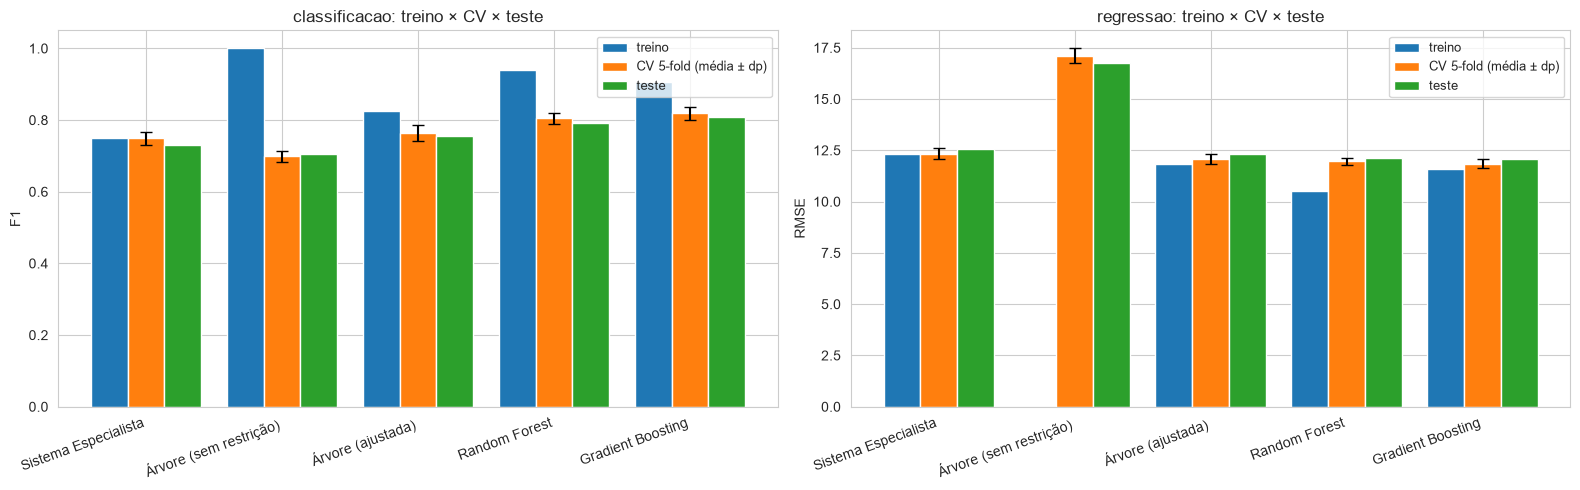

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (problema, gen) in zip(axes, [("classificacao", gen_c), ("regressao", gen_r)]):
    nome_m = METRICA_PRINCIPAL[problema]
    x = np.arange(len(gen))
    ax.bar(x - 0.27, gen[f"{nome_m}_treino"], 0.27, label="treino")
    ax.bar(x, gen["cv_media"], 0.27, yerr=gen["cv_desvio"], capsize=4, label="CV 5-fold (média ± dp)")
    ax.bar(x + 0.27, gen[f"{nome_m}_teste"], 0.27, label="teste")
    ax.set_xticks(x)
    ax.set_xticklabels(gen.index, rotation=20, ha="right")
    ax.set_ylabel(nome_m)
    ax.set_title(f"{problema}: treino × CV × teste")
    ax.legend(fontsize=9)
plt.tight_layout()
salvar_fig("generalizacao_treino_cv_teste")
plt.show()

## 3. Curvas de aprendizado (viés × variância)

Desempenho no treino e na validação (5 folds) em função do tamanho do treino.
Curvas distantes = **alta variância** (o modelo decora o treino); curvas próximas, mas
em um patamar ruim = **alto viés**.

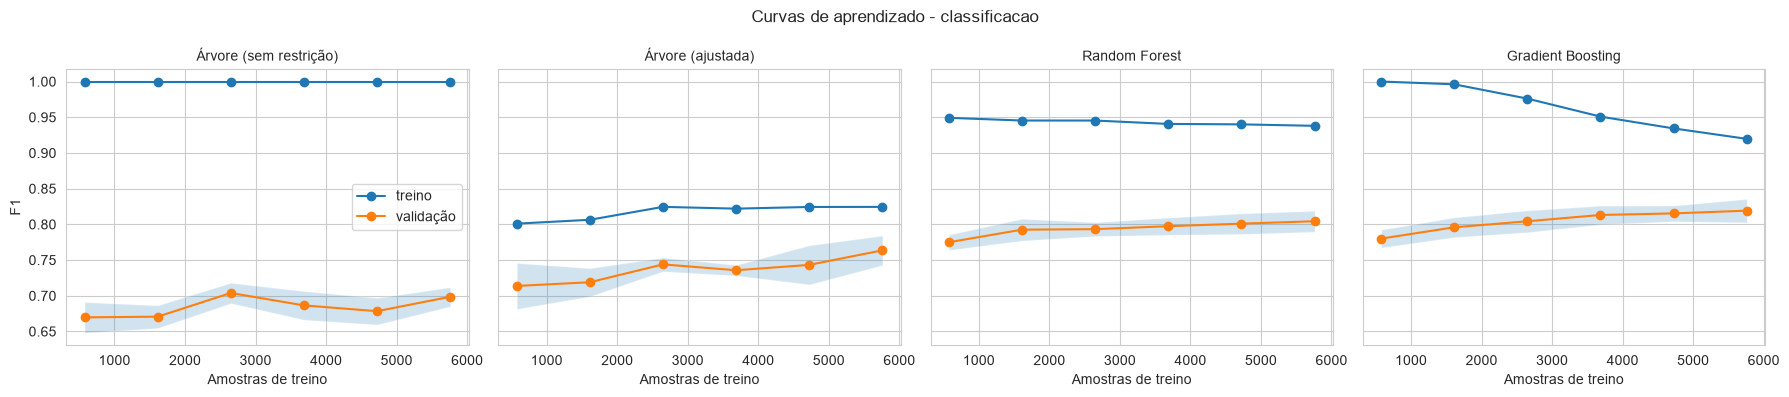

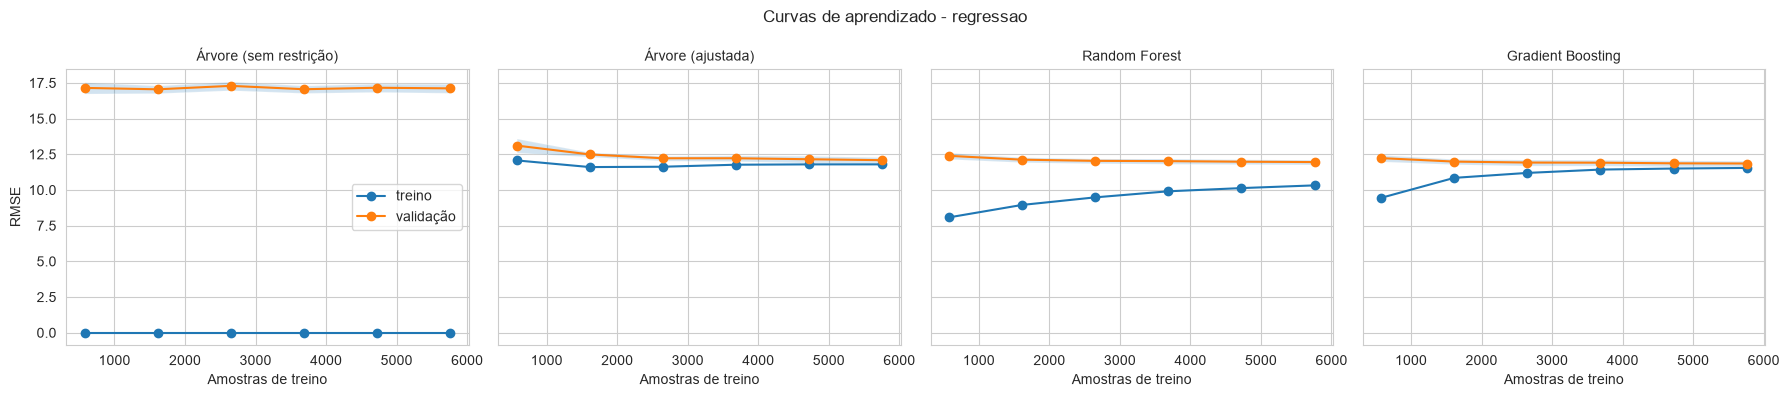

In [6]:
tamanhos = np.linspace(0.1, 1.0, 6)
for problema in ("classificacao", "regressao"):
    X_train, _, y_train, _ = carregar_split(problema)
    ml = {n: m for n, m in carregar_modelos(problema).items() if not isinstance(m, SistemaEspecialista)}
    fig, axes = plt.subplots(1, len(ml), figsize=(4.5 * len(ml), 4), sharey=True)
    for ax, (nome, m) in zip(axes, ml.items()):
        n, tr, va = learning_curve(clone(m), X_train, y_train, train_sizes=tamanhos,
                                   cv=cv[problema], scoring=SCORING_CV[problema], n_jobs=-1)
        tr, va = np.abs(tr), np.abs(va)
        ax.plot(n, tr.mean(1), "o-", label="treino")
        ax.plot(n, va.mean(1), "o-", label="validação")
        ax.fill_between(n, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
        ax.set_title(nome, fontsize=10)
        ax.set_xlabel("Amostras de treino")
    axes[0].set_ylabel(METRICA_PRINCIPAL[problema])
    axes[0].legend()
    plt.suptitle(f"Curvas de aprendizado - {problema}")
    plt.tight_layout()
    salvar_fig(f"curvas_aprendizado_{problema}")
    plt.show()